<a href="https://colab.research.google.com/github/QuirozAlaniz/Actividad-EDA/blob/main/Actividad_EDA_predictivo_bank_marketing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: análisis exploratorio de datos para analítica predictiva
## Caso: suscripción a un depósito a plazo tras una llamada de telemarketing bancario

Programación para Analítica Descriptiva y Predictiva · Tema : EDA con Analítica Predictiva
Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

**Nombre del estudiante:** Francisco Daniel Quiroz Alaniz  

**Matrícula:** 269723

**Fecha:** 10 de octubre de 2026

## Propósito

Aplicar, de forma individual y sobre un conjunto de datos nuevo, el procedimiento de análisis exploratorio para analítica predictiva revisado en el notebook guiado del caso Telco. El producto de la actividad es una **hoja de decisiones** de preprocesamiento y modelado, sustentada en evidencia obtenida con el código.

No se entrena ningún modelo en esta actividad.

## Instrucciones de entrega

1. Completa las celdas de código y las de texto marcadas con **Tu predicción**, **Tu observación** o **Tu respuesta**.
2. Antes de entregar, ejecuta el notebook completo con *Kernel > Restart & Run All*. El notebook debe ejecutarse de principio a fin sin errores.
3. Guarda el archivo como `Apellido_Nombre_EDA_predictivo.ipynb` y entrégalo en el medio indicado por el profesor.
4. La actividad es individual. Las predicciones deben escribirse **antes** de ejecutar cada celda de código.

## Reglas de trabajo

- Usa solo el conjunto `df` y las librerías ya importadas.
- Después de la división de la parte C, el conjunto `prueba` **no se utiliza** en ninguna celda.
- Usa `random_state=42` en toda operación aleatoria, para que los resultados sean comparables.
- Las observaciones y las decisiones citan cifras obtenidas con tu propio código.

## Conjunto de datos y fuente

**Bank Marketing** (archivo `bank-additional-full.csv`), del repositorio UCI de aprendizaje automático. Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués. El conjunto contiene 41,188 contactos ordenados por fecha, de mayo de 2008 a noviembre de 2010, y 21 columnas.


**Problema predictivo.** Clasificación binaria: dadas las características de un cliente y del contexto de la campaña, predecir si el cliente contratará el depósito a plazo (`y`).

**Diccionario de datos**

| Columna | Contenido |
| --- | --- |
| `age` | Edad del cliente |
| `job`, `marital`, `education` | Ocupación, estado civil y escolaridad |
| `default`, `housing`, `loan` | Si tiene crédito en incumplimiento, crédito hipotecario y préstamo personal |
| `contact` | Medio de contacto: `cellular` o `telephone` |
| `month`, `day_of_week` | Mes y día de la semana del último contacto de la campaña actual |
| `duration` | Duración de la última llamada, en segundos |
| `campaign` | Número de contactos con este cliente en la campaña actual, incluido el último |
| `pdays` | Días transcurridos desde el último contacto de una campaña anterior; `999` indica que no fue contactado antes |
| `previous` | Número de contactos antes de la campaña actual |
| `poutcome` | Resultado de la campaña anterior: `success`, `failure` o `nonexistent` |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Indicadores económicos trimestrales o mensuales: variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados |
| `y` | Variable objetivo: `yes` si el cliente contrató el depósito, `no` si no |

## 1. Preparación del entorno y carga de datos (celda proporcionada)

Ejecuta la celda sin modificarla. Si el archivo no está en la carpeta, la celda lo descarga de una copia pública del conjunto; si ya está, lo reutiliza. El archivo usa punto y coma como separador.

In [110]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"
COLORES_CLASE = {"no": AZUL, "yes": NARANJA}
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-additional-full.csv"
archivo = "bank_marketing.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

df = pd.read_csv(archivo, sep=";")

numericas = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

print("Filas y columnas:", df.shape)

Filas y columnas: (41188, 21)


## Parte A. Definición del problema

**Por qué.** Un EDA predictivo se orienta por preguntas que se responden antes de calcular nada. Una de ellas, qué información estará disponible al momento de predecir, decide qué variables pueden entrar al modelo.

Completa la columna **Respuesta** de la siguiente tabla, editando esta celda.

| Pregunta | Respuesta |
| --- | --- |
| ¿Qué es una observación? | Es un cliente con catacterísticas relativas a su perfil como cliente de un banco portugués a quien se le invitará a adquirir un depósito a plazo|
| ¿Qué se predice? | Si el cliente va a contratar o no el depósito a plazo|
| ¿Qué tipo de problema es? | De clasificación binario|
| ¿En qué momento se haría la predicción y qué información existiría entonces? |La predicción se haría antes de hacer la llamada al cliente, y se contaría con información personal del cliente como empleo, escolaridad, edad, e información sobre interacciones pasadas |
| ¿Qué columnas no deberían usarse como características y por qué? | Todas deberían usarse como características (a excepción de la variable objetivo y duration) porque no tenemos columna de ID y todas aportan valor, incluso si se les ha contactado por teléfono o celular, aunque creo que aportaría poco valor por el uso tan extensivo que se hace del celular actualmente, no usar duration porque eso lo sabremos hasta después de que se realice la llamada|

**Tu predicción.** ¿Qué porcentaje de los contactos esperas que haya terminado en contratación del depósito?
\
Pienso que el 20% pudieron haber contratado el depósito, como regla de Pareto del 80-20

## Parte B. Descripción de los datos y detección de problemas de calidad, conjunto total

**Por qué.** La descripción (tamaño, tipos, significado de las columnas) y la detección de problemas con criterios estructurales o del dominio no usan la variable objetivo ni calculan parámetros que se aplicarán al modelo. Por eso se hacen con el conjunto total `df`, antes de dividir. Esta parte **detecta y cuantifica**; las decisiones de tratamiento se toman en la hoja de la parte G.

Las verificaciones de calidad de CRISP-DM que se piden son: consistencia de valores, cantidad y distribución de valores nulos, y valores fuera de rango.

**Pista.** En este conjunto los faltantes en variables categóricas se codifican con el texto `unknown`, no con `NaN`.

**Tu predicción.** ¿Habrá valores `NaN`? ¿En qué columnas esperas encontrar `unknown` y en cuántas filas?
\
Pienso que habrá aproximadamente 1000 filas con unknown en la columna "previous" porque puede que no se haya contactado a la persona previamente.
\
Creo que habrá NaN en la columna "Education" porque puede ser que en esos registros manuales al momento de dar de alta un cliente, pueda generar errores de tecleado.

In [111]:
# B1. Estructura. Escribe el código que muestre:
#  - las dimensiones del conjunto,
print("El número de filas y columnas es:", df.shape)

#  - el tipo de dato de cada columna,
print()
print("Los nombres de las columnas y el tipo de dato que albergan es:")
print(df.info() )
print()

#  - el número de valores únicos por columna, de menor a mayor.
print("Los números de valores únicos por columna de menor a mayor es:")
print( df.nunique().sort_values() )

El número de filas y columnas es: (41188, 21)

Los nombres de las columnas y el tipo de dato que albergan es:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rat

In [112]:
# B2. Valores faltantes. Escribe el código que muestre:
#  - el total de valores NaN del conjunto,
print("El número de faltantes en todo el conjunto de datos es:", df.isna().sum().sum() )

#  - para las columnas categóricas, cuántas filas tienen "unknown" (solo las columnas con al menos una),
print()
columnas = list(df.columns)           #Obtenemos todas las columnas del dataframe y las guardamos en una lista
categoricas =[]
for i in columnas:                    #Este ciclo for verifica si la columna es "object" y lo pone en una lista llamada "categoricas"
  if df[i].dtype == "object":
    categoricas.append(i)

conteo = (df[categoricas] == "unknown").sum()        #Seleccionamos el dataframe con las columnas categóricas y filtramos las que son "unknown" y las contamos con .sum()
conteo = conteo[conteo>0]
tabla1 = pd.DataFrame({"columna":conteo.index ,"numero_unknown":conteo.values} )


#  - ese conteo como porcentaje de las filas.
tabla1["porcentaje_unknown"] = (tabla1["numero_unknown"]/len(df))*100   #Agregamos la columna de "porcentaje_unknown"
print(tabla1)

El número de faltantes en todo el conjunto de datos es: 0

     columna  numero_unknown  porcentaje_unknown
0        job             330            0.801204
1    marital              80            0.194231
2  education            1731            4.202680
3    default            8597           20.872584
4    housing             990            2.403613
5       loan             990            2.403613


In [113]:
# B3. Duplicados. Escribe el código que cuente las filas completamente idénticas.
print("El número de filas completamente idénticas son:", df.duplicated().sum())

El número de filas completamente idénticas son: 12


In [114]:
# B4. Consistencia entre columnas relacionadas. Escribe el código que muestre:
#  - cuántas filas tienen pdays igual a 999 y qué porcentaje es,
numero = (df["pdays"] == 999).sum()
print("El número de filas que tienen pdays = 999 es:", numero, "lo que representa el", (numero/len(df))*100, "%" )

#  - una tabla de contingencia entre poutcome y (previous == 0),
print()
print( pd.crosstab(df.poutcome, df.previous == 0) ) #El poutcome dice success, failure o unknown dependiendo del resultado de la campaña anterior.
                                                    #Y previous tiene el número de contactos antes de la campaña actual

#  - una tabla de contingencia entre poutcome y (pdays == 999). #pdays es el número de contactos antes de la campaña, 999 significa que no ha sido contactado antes
# Pista: pd.crosstab.
print()
print( pd.crosstab(df.poutcome, df.pdays == 999))

El número de filas que tienen pdays = 999 es: 39673 lo que representa el 96.32174419733903 %

previous     False  True 
poutcome                 
failure       4252      0
nonexistent      0  35563
success       1373      0

pdays        False  True 
poutcome                 
failure        142   4110
nonexistent      0  35563
success       1373      0


In [115]:
# B5. Rangos según el dominio. Escribe el código que muestre:
#  - la edad mínima y máxima,
maxima = df["age"].max()
minima = df["age"].min()
print("La edad máxima de los clientes es:", maxima, "La edad mínima de los clientes es:" , minima )

#  - cuántas llamadas tienen duration igual a 0,
duracion0 = (df["duration"] == 0 ).sum()
print("El número de llamadas con duración igual a cero es:", duracion0)

#  - el mínimo y el máximo de campaign, #campaign tiene el número de contactos con este cliente en la campaña actual, incluido el último
maximo = df["campaign"].max()
minimo = df["campaign"].min()
print("El número máximo de campaign es:", maximo, "y el número mínimo es:", minimo)

#  - cuántas filas tienen previous negativo. #previous tiene el número de contactos antes de la campaña actual
previous_negativo = (df["previous"]<0).sum()
print("El número de filas que tienen previous negativo es:", previous_negativo)

La edad máxima de los clientes es: 98 La edad mínima de los clientes es: 17
El número de llamadas con duración igual a cero es: 4
El número máximo de campaign es: 56 y el número mínimo es: 1
El número de filas que tienen previous negativo es: 0


**Tu observación.** Resume los problemas de calidad que encontraste, con su cifra, y di cuáles dependen del significado de la variable.
\
Un problema que encontré está en las tablas de contingencia.
\
En la primera tabla filtramos los valores que tenían previous == 0, que son las personas a las que no se les había contactado previamente, lo cual nos arrojó que failure eran 0.
\
Mientras que si hacemos lo mismo con pdays = 999, que es equivalente a previous == 0, nos arroja que failure eran 4110, lo cual es inconsistente porque ambas tablas de contingencia deberían de dar exactamente lo mismo por ser condiciones equivalentes.
\
El problema es que no podemos decir que se tuvo un "failure" en el resultado de la campaña anterior cuando esas personas nunca fueron contactadas.
\
En resumen, se necesita investigar más a fondo sobre lo que en realidad está pasando con esas columnas para verificar si son errores efectivamente.

**Tu respuesta.** ¿Qué harías con `unknown` en `default`: tratarla como una categoría más, imputarla o eliminar las filas? Justifica con lo observado. Escribe tu respuesta aquí.
\
El "unknown" en default se debe dejar como está para tratarla como una categoría más. Si eliminamos las filas donde se encuentra, eliminaríamos el 20.8 \% del total de los datos, lo cual sería una gran pérdida de información.

In [116]:
#Código adicional para saber un poco más del unknown de la columna default
unknown_default = (df["default"] == "unknown").sum()
print("El número de unknowns en la columna default es:", unknown_default, "lo que representa un", (unknown_default/len(df))*100, "%", "del total de filas" )

El número de unknowns en la columna default es: 8597 lo que representa un 20.87258424783918 % del total de filas


## Parte C. División en entrenamiento y prueba

**Por qué.** La exploración que sigue relaciona características con la variable objetivo y fundamenta decisiones de modelado. Si usara los datos de prueba, esas decisiones incorporarían información de los datos con los que después se evaluará el modelo (fuga de información). Por eso se aparta el conjunto de prueba y no se vuelve a tocar hasta la evaluación final.

**Especificaciones.**

- 80% entrenamiento y 20% prueba.
- División estratificada según `y`.
- `random_state=42`.
- Guarda los conjuntos como `entrenamiento` y `prueba`.
- Crea `ent`, una copia de `entrenamiento`, y agrega a `ent` la columna `suscribe` con 1 si `y` es `yes` y 0 si es `no`.

**Tu predicción.** ¿La proporción de contratación será igual en entrenamiento y prueba? ¿Por qué? Escribe tu respuesta aquí, antes de ejecutar la celda de código.
\
Si asumimos que el conjunto de datos de prueba son representativos con respecto a la cantidad de los datos de entrenamiento en todas las variables predictoras, entonces lo más probable es que la proporción de contratación también lo sea porque estaríamos eligiendo conjuntos estadísticamente equivalentes.

In [117]:
# C1. Escribe el código de la división y la creación de ent y de la columna suscribe.
# Después imprime:
#  - el tamaño de entrenamiento y de prueba,
entrenamiento, prueba = train_test_split(df, test_size = 0.2, stratify = df["y"], random_state = 42)
print("El tamaño del conjunto de datos de entrenamiento es:", len(entrenamiento))
print()
print("El tamaño del conjunto de datos de prueba es:", len(prueba))

ent = entrenamiento.copy()   #Copia del dataframe de entrenamiento
ent["suscribe"] = entrenamiento["y"].map({"yes":1, "no":0})

#  - el porcentaje de contratación (y igual a yes) en cada uno.
print()
print("Las proporciones de yes:1 y no=0 en el dataset de entrenamiento son:\n",ent["suscribe"].value_counts(normalize = True), sep="")
print()
print("Las proporciones de yes y no en el dataset de prueba son:\n", prueba["y"].value_counts(normalize = True), sep="")


El tamaño del conjunto de datos de entrenamiento es: 32950

El tamaño del conjunto de datos de prueba es: 8238

Las proporciones de yes:1 y no=0 en el dataset de entrenamiento son:
suscribe
0    0.887344
1    0.112656
Name: proportion, dtype: float64

Las proporciones de yes y no en el dataset de prueba son:
y
no     0.887351
yes    0.112649
Name: proportion, dtype: float64


**Verificación (celda proporcionada).** Ejecútala para comprobar que la división coincide con las especificaciones. Si muestra que no se superó, revisa `test_size`, `stratify` y `random_state`.

In [118]:
if entrenamiento.shape[0] == 32950 and prueba.shape[0] == 8238 and "suscribe" in ent.columns and abs(ent["suscribe"].mean() - 0.1127) < 0.0005:
    print("Verificación superada.")
else:
    print("Verificación no superada: revisa la división y la columna suscribe.")

Verificación superada.


**Tu observación.** Compara las dos proporciones con tu predicción.
\
Las proporciones en ambos conjuntos son: no: 88.7\% y yes:11.2\%
\
Entonces podemos decir que sí son proporcionales como había predicho.

**A partir de aquí el conjunto `prueba` no se usa.** Todo el análisis trabaja sobre `ent`.

## Parte D. Exploración del objetivo y de las variables numéricas, entrenamiento

### D1. Variable objetivo

**Por qué.** En clasificación, la distribución de la variable objetivo condiciona las métricas de evaluación, la validación y la necesidad de rebalancear. Es lo primero que se examina.

**Tu predicción.** Si un modelo respondiera siempre `no`, ¿qué exactitud obtendría?
\
En el hipotético caso de que el modelo construido respondiera siempre "no", entonces tendría el 88.7% de exactitud, dado que del 100% de sus respuestas, le atinaría al 88.7% porque hay 88.7% "no".
\
Pero si cambiamos de conjunto de datos, quizá la exactitud se desplome porque no podemos esperar siempre un 88.7% de "no" en cualquier conjunto de datos

El número por clases en la variable objetivo es:
 y
no     29238
yes     3712
Name: count, dtype: int64

La proporción de las clases en la variable objetivo es:
 y
no     88.734446
yes    11.265554
Name: proportion, dtype: float64


La razón entre la clase mayoritaria y la minoritaria es: 7.876616379310344

La exactitud por obtener siempre un no es: 88.73444613050076



Text(0.5, 1.0, 'Número de clientes por clase')

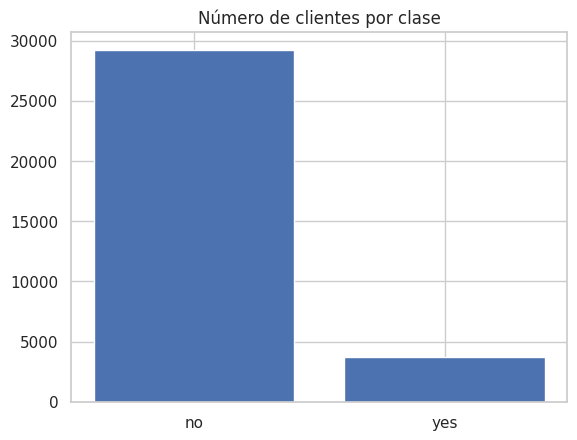

In [119]:
# D1. Escribe el código que muestre:
#  - el número y el porcentaje de clientes de cada clase en ent,
proporcion1 = ent["y"].value_counts(normalize = True)*100
proporcion2 = ent["y"].value_counts()

print(f'El número por clases en la variable objetivo es:\n {proporcion2}', sep="")
print()
print(f'La proporción de las clases en la variable objetivo es:\n {proporcion1}', sep="")
print()


#  - la razón entre la clase mayoritaria y la minoritaria,
mayoritaria = max(proporcion1.values)
minoritaria = min(proporcion1.values)
print()
print(f'La razón entre la clase mayoritaria y la minoritaria es: {mayoritaria/minoritaria}')

#  - la exactitud de responder siempre "no",
exactitud_no = proporcion1["no"]
print()
print(f'La exactitud por obtener siempre un no es: {exactitud_no}')

#  - una gráfica de barras con el número de clientes por clase.
print()
fig, ax = plt.subplots()
ax.bar(proporcion2.index, proporcion2.values)
plt.title("Número de clientes por clase")

**Tu observación.** Compara con tu predicción de las partes A y D y explica qué implica para la evaluación del modelo.
\
Yo había predicho que el 25% contrataba el plan, pero resultó que en realidad es alrededor del 11.2%.
\
La proporción obedece a que en el conjunto de todos los datos, esa proporción es la misma, y es importante que sea así para que el modelo aprenda de todos los casos, por ejemplo si solo entrenáramos con datos que tienen "si", entonces no sabría reconocer cuándo clasificar a alguno como "no".  

### D2. Variables numéricas según la clase

**Por qué.** Para cada característica numérica interesa cómo se distribuye en cada clase: si lo hace de forma distinta, la variable separa a quienes contratan de quienes no. Se compara la mediana porque es resistente a valores extremos.

**Tu predicción.** ¿Cuáles de las variables numéricas esperas que más difieran entre quienes contratan y quienes no?
\
Las variables numéricas que difieren entre quienes contratan y quienes no son la "emp.var.rate", que mide las condiciones de empleo y la de "duration" porque si alguien contrató lo más probable es que la llamada se haya alargado para que el cliente pudiera hacer el proceso de contratación.

La tabla con la mediana de cada columna numérica es la siguiente:
 
       age  duration  campaign  pdays  previous  emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed
y                                                                                                                  
no   38.0     164.0       2.0  999.0       0.0           1.1          93.918          -41.8      4.857       5195.8
yes  37.0     448.0       2.0  999.0       0.0          -1.8          93.200          -40.4      1.266       5099.1

Los diagramas de caja son los siguientes:


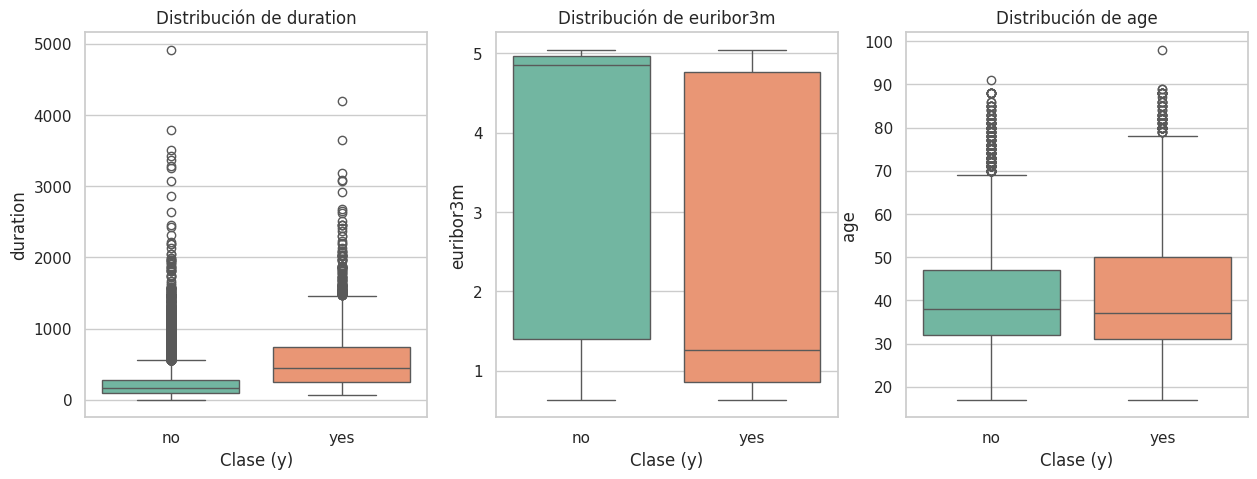

In [120]:
# D2. Escribe el código que muestre:
#  - la mediana de cada variable numérica (lista numericas) por clase de y,
numericas = []
for i in ent.columns:
  if i == "suscribe":                                       #si la columna es "suscribe" entonces pasar al siguiente automáticamente para que no entre a la lista
    continue
  if ent[i].dtype == float or ent[i].dtype == int:          # or funciona como una disyunción inclusiva
    numericas.append(i)

tabla = ent.groupby("y")[numericas].agg("median")
print(f'La tabla con la mediana de cada columna numérica es la siguiente:\n \n {tabla}', sep="")
print()


#  - diagramas de caja por clase de y de al menos tres variables numéricas que elijas.
print("Los diagramas de caja son los siguientes:")
fig, axes = plt.subplots(1, 3, figsize=(15, 5) )
variables = ["duration", "euribor3m", "age"]
for i, var in enumerate(variables):
    sns.boxplot(data=ent, x='y', y=var, ax=axes[i], palette="Set2", hue = "y")
    axes[i].set_title(f'Distribución de {var}')
    axes[i].set_xlabel('Clase (y)')
    axes[i].set_ylabel(var)

**Tu observación.** Indica qué variables separan las clases y cuáles no, con las medianas.
\
\
Las variables que más se observa, separan las clases son la duración de la llamada y el euriborn3m, que es el tipo de interés al que los bancos se prestan dinero en Europa.
\
Solo le atiné al de duración de la llamada.

### D3. Valores atípicos

**Por qué.** Los modelos lineales, las máquinas de soporte vectorial y las redes neuronales son sensibles a valores extremos y a la escala; los árboles de decisión y sus conjuntos no lo son. El EDA documenta el problema y la decisión depende del modelo.

Los límites de Tukey (1.5 veces el rango intercuartílico) se calculan con los cuartiles de los datos, por lo que se obtienen con el conjunto de entrenamiento.

**Tu predicción.** ¿Qué variables numéricas esperas que tengan más registros fuera de los límites de Tukey?
\
\
La duración de la llamada definitivamente podría ser la que más tenga más registros fuera de los límites de Tukey porque depende mucho de factores sobre los que no tenemos control.

In [121]:
# D3. Escribe el código que calcule, con ent, los límites inferior y superior de Tukey
# de cada variable de la lista numericas y muestre cuántos registros quedan fuera de ellos por variable.
IQR = []
liminf = []
limsup = []
for i in numericas:
  iqr_25 = ent[i].quantile(0.25)
  iqr_75 = ent[i].quantile(0.75)
  valor = iqr_75-iqr_25
  IQR.append(valor)
  inf = iqr_25 -valor*1.5
  sup = iqr_75 + valor*1.5
  liminf.append(inf)
  limsup.append(sup)

  #Hacemos la tabla de rango intercuartílico por columna numérica
tabla = pd.DataFrame({"Columna":numericas, "Rango":IQR, "Lim. Inferior":liminf, "Lim. Superior":limsup})


In [122]:
numericas = ent[tabla["Columna"]].copy()
for index, fila in tabla.iterrows():
  col = fila["Columna"]
  inf = fila["Lim. Inferior"]
  sup = fila["Lim. Superior"]
  numericas[col] = (ent[col] < inf) | (ent[col] >sup)
conteo = numericas.sum()
tabla["Outliers"] = conteo.values
display(tabla)

,Columna,Rango,Lim. Inferior,Lim. Superior,Outliers
0,age,15.000,9.5000,69.5000,368
1,duration,216.000,-221.0000,643.0000,2366
2,campaign,2.000,-2.0000,6.0000,1916
3,pdays,0.000,999.0000,999.0000,1226
4,previous,0.000,0.0000,0.0000,4534
5,emp.var.rate,3.200,-6.6000,6.2000,0
6,cons.price.idx,0.919,91.6965,95.3725,0
7,cons.conf.idx,6.300,-52.1500,-26.9500,359
8,euribor3m,3.617,-4.0815,10.3865,0
9,nr.employed,129.000,4905.6000,5421.6000,0


**Tu respuesta.** ¿Eliminarías los registros atípicos de alguna variable? Justifica por variable con lo que sabes de su significado.
\
\
Sorpresivamente la columna que tiene más outliers es la columna "previous", que cuenta el número de contactos antes de la campaña actual.
\
Pero en segundo lugar tenemos la que predije tendría muchos outliers: duration.
\
No eliminaría los registros de duration.
\
Tampoco eliminaría los outliers de "previous" porque los outliers más altos tienen el valor de 7 (siete outliers), mientras que los más bajos tienen el valor de 0.  Dicho esto, los que tienen el valor de 4 a 6 están cerca de la mediana.

### D4. Asimetría y re-expresión

**Por qué.** Cuando una variable tiene asimetría fuerte, una transformación monótona (raíz cuadrada o logaritmo) puede acercar su distribución a una forma simétrica. Un modelo sensible a la escala se beneficia; uno basado en árboles no. La asimetría guía la decisión.

**Tu predicción.** ¿Cuál transformación, raíz cuadrada o logaritmo (`np.log1p`), reducirá más la asimetría de `campaign`?
\
Creo que el logaritmo es el que reduciría más la asimetría por ser una función que puede mapear valores muy altos a otros más bajos.

,variable,original,raiz,logaritmo
0,age,0.760819,0.426057,0.132406
1,duration,3.326612,1.203716,-0.430172
2,campaign,4.742537,2.162976,1.350996


Text(0.5, 1.0, 'Asimetría campaign transformada logarítmica')

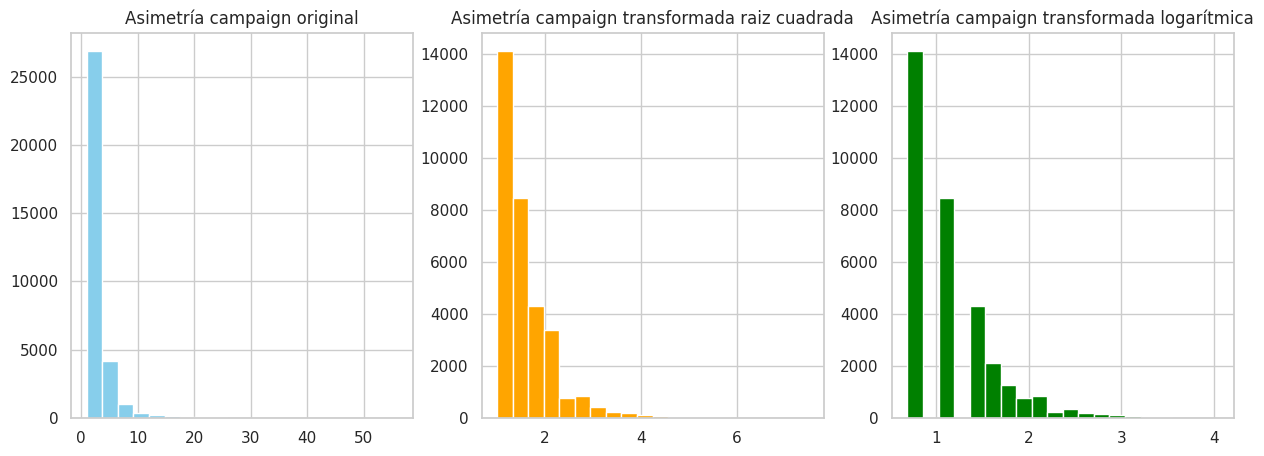

In [123]:
# D4. Escribe el código que muestre una tabla con la asimetría original, con raíz cuadrada y con
# logaritmo (np.log1p) de las variables age, duration y campaign, calculada con ent.

datos = pd.DataFrame({"variable": ["age", "duration", "campaign"],
              "original":[ent["age"].skew(), (ent["duration"]).skew(), (ent["campaign"]).skew()],
              "raiz":[np.sqrt(ent["age"]).skew(), np.sqrt(ent["duration"]).skew(), np.sqrt(ent["campaign"]).skew()],
              "logaritmo":[np.log1p(ent["age"]).skew(), np.log1p(ent["duration"]).skew(), np.log1p(ent["campaign"]).skew() ]       })
display(datos)
print()

# Después grafica los histogramas de campaign: original y transformada.
fig, axes = plt.subplots(1, 3, figsize = (15, 5))
axes[0].hist(ent["campaign"], bins=20, color="skyblue", edgecolor="white")
axes[0].set_title("Asimetría campaign original")
axes[1].hist(np.sqrt(ent["campaign"]), bins=20, color="orange", edgecolor="white")
axes[1].set_title("Asimetría campaign transformada raiz cuadrada")
axes[2].hist(np.log1p(ent["campaign"]), bins=20, color="green", edgecolor="white")
axes[2].set_title("Asimetría campaign transformada logarítmica")

**Tu observación.** Reporta las asimetrías y decide qué transformación, si alguna, aplicarías a cada variable.
\
Como podemos observar en la tabla, la asimetría de la variable "age" baja la asimetría mucho más usando la transformación logarítmica que con la raiz cuadrada.
\
En cuanto la variable duration, que tiene una cola muy larga hacia la derecha, se aplana más con la transformación logarítmica que con la raíz cuadrada, al igual que la variable campaign.
\
Como lo predicho, la transformación logarítmica tiene un potencial más robusto para corregir asimetrías.
\
Sin embargo en el caso de campaign, la asimetría llegó a ser negativa y como podemos ver en el histograma de las asimetrías de esta variable, la asimetría que mejor se comporta es la realizada con la raíz cuadrada, porque la arrojada por la transformación logarítmica deja espacios huecos, lo que significa que no siempre es mejor la transformación que más acerca a cero sino la que ajusta mejor la curva sin sobreajustarla.

## Parte E. Exploración de las variables categóricas, entrenamiento

**Por qué.** Para una característica categórica, la medida natural es la **tasa de contratación por categoría** comparada con la tasa global, junto con el número de clientes: una tasa calculada con pocos registros es poco confiable.

**Tu predicción.** ¿Qué variable categórica esperas que tenga las categorías con mayor tasa de contratación? ¿Y cuáles esperas que casi no separen las clases?
\
Esperaría que las variables de "education", "job" y "loan" tengan las mayores tasas de contratación porque son variables que pienso, influyen en la decisión de adquirir un nuevo compromiso.
\
Las que creo que no influyen mucho son "marital" y "contact".

In [124]:
# E1. Escribe el código que muestre:
#  - el número de categorías de cada variable de la lista categoricas,
categoricas = []
for i in ent.columns:
  if ent[i].dtype == "object":
    categoricas.append(i)

print( "El número de categorías de cada columna categórica es:\n", ent[categoricas].nunique(), sep="" )
print()

#  - la tasa global de contratación en ent.
tasa = ent["suscribe"].mean()
print(f'La tasa global de contratación es: {tasa:.2%}')

El número de categorías de cada columna categórica es:
job            12
marital         4
education       8
default         3
housing         3
loan            3
contact         2
month          10
day_of_week     5
poutcome        3
y               2
dtype: int64

La tasa global de contratación es: 11.27%


In [125]:
# E2. Escribe el código que construya una tabla con el número de clientes y la tasa de contratación (en %)
# de cada categoría de cada variable de categoricas. Muestra:
#  - las 12 categorías con mayor tasa,
#  - las 8 con menor tasa,
#  - las tablas de default, housing, loan y day_of_week.
# Pista: reutiliza el patrón melt + groupby + agg del notebook guiado del caso Telco.

categoricas = []
for i in ent.columns:
  if i == "y":
    continue
  if ent[i].dtype == "object":
    categoricas.append(i)

largo = ent.melt(id_vars=["suscribe"], value_vars = categoricas, var_name = "variable", value_name = "categoria")
tasas = largo.groupby(["variable", "categoria"])["suscribe"].agg(clientes = "count", tasa_contratacion = "mean")
tasas["tasa_contratacion"] = tasas["tasa_contratacion"]*100

print()
print("Las 12 categorías con mayor tasa de contratación son:\n", tasas.sort_values("tasa_contratacion", ascending = False).head(12), sep="")
print()
print("Las ocho categorías con menor tasa de contratación son:\n", tasas.sort_values("tasa_contratacion", ascending = True).head(8), sep ="")
print()
print(tasas.loc[["default", "housing", "loan", "day_of_week"]])


Las 12 categorías con mayor tasa de contratación son:
                      clientes  tasa_contratacion
variable  categoria                              
poutcome  success         1105          64.886878
month     dec              143          50.349650
          mar              436          49.770642
          sep              464          44.612069
          oct              587          43.270869
job       student          711          30.520394
          retired         1366          25.475842
month     apr             2085          20.479616
education illiterate        16          18.750000
marital   unknown           65          16.923077
education unknown         1397          14.817466
contact   cellular       20908          14.702506

Las ocho categorías con menor tasa de contratación son:
                       clientes  tasa_contratacion
variable  categoria                               
default   yes                 3           0.000000
          unknown          6940    

Text(0.5, 1.0, 'Tasa de contratación por categoría de contact')

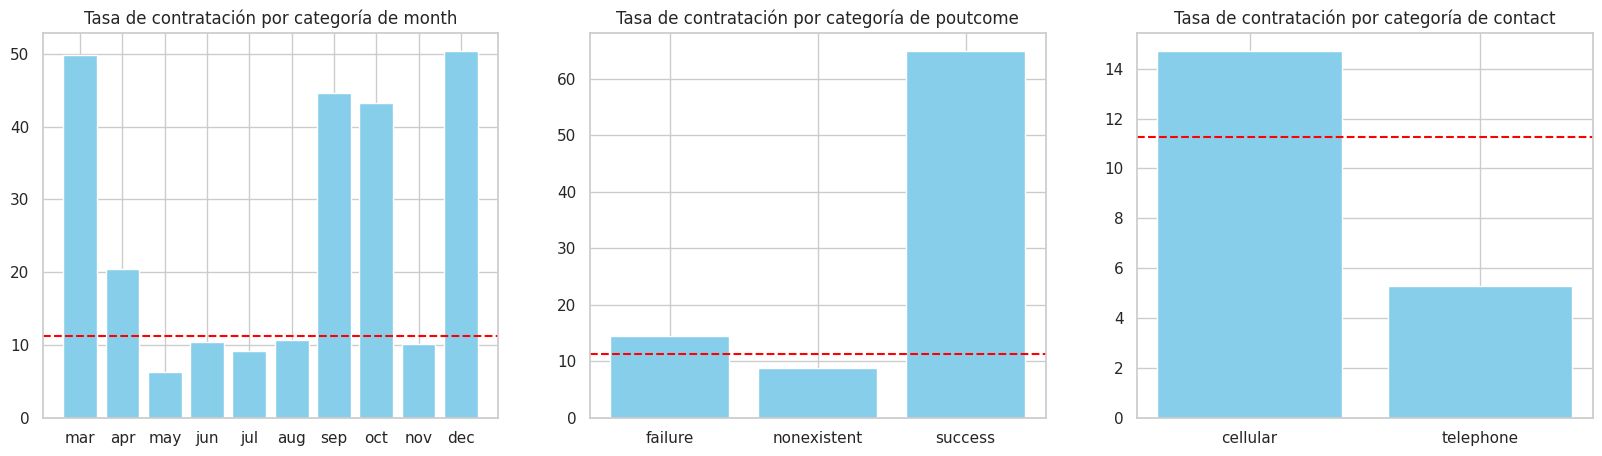

In [126]:
# E3. Escribe el código que grafique la tasa de contratación por categoría de month (en orden
# cronológico: mar, apr, may, jun, jul, aug, sep, oct, nov, dec), poutcome y contact,
# con una línea horizontal en la tasa global.

tasa_global = ent["suscribe"].mean()*100
month = ["mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
outcome = ["failure", "nonexistent", "success"]
contac = ["cellular", "telephone"]

tasas_month = tasas.loc["month"].loc[month]["tasa_contratacion"]
p_outcome = tasas.loc["poutcome"].loc[outcome]["tasa_contratacion"]
contact_ = tasas.loc["contact"].loc[contac]["tasa_contratacion"]


fig, axes = plt.subplots(1, 3, figsize = (20, 5))
axes[0].bar(month, tasas_month, color = "skyblue")
axes[0].set_title("Tasa de contratación por categoría de month")
axes[0].axhline(tasa_global, color = "red", linestyle = "--")
axes[1].bar(outcome, p_outcome, color = "skyblue" )
axes[1].axhline(tasa_global, color = "red", linestyle = "--")
axes[1].set_title("Tasa de contratación por categoría de poutcome")
axes[2].bar(contac, contact_, color ="skyblue")
axes[2].axhline(tasa_global, color = "red", linestyle = "--")
axes[2].set_title("Tasa de contratación por categoría de contact")


**Tu observación.** Identifica las categorías con mayor y menor tasa, con su tasa y su número de clientes, y las variables que casi no separan las clases.
\
\
Las categorías con mayor tasa son : poutcome que es el resultado de la campaña anterior con una tasa de éxito mayor al 64% lo que representa a 1105 personas, la categoría del mes de diciembre con arriba del 50% que representa a 143 personas, le siguen marzo, septiembre y octubre.
\
Otra que llama la atención es los estudiantes poco arriba del 30%.
\
\
Por su parte, las categorías que tienen menor tasa son:
\
"unknown" de la columna default, con apenas 5% que representa 6940 personas, aquéllas personas contactadas por teléfono: 12042 personas con 5.2 % de contratación y las del mes de mayo con 11011 personas y 6.3% de contratación.

**Tu respuesta.** En `default`, ¿qué indica que la categoría `unknown` tenga una tasa de contratación distinta a la de `no`? ¿Qué hay que cuidar con las categorías `yes` de `default` o `illiterate` de `education`? Escribe tu respuesta aquí.

## Parte F. Relaciones entre características y variable `duration`, entrenamiento

### F1. Relaciones entre características

**Por qué.** Dos características muy relacionadas son redundantes y pueden causar inestabilidad en modelos lineales (colinealidad).

**Tu predicción.** ¿Qué pares de indicadores económicos (lista `macro`) esperas que estén más correlacionados?
\
El Euribor y el índice de precios, porque el Euribor es la tasa de interés interbancaria de Europa y el índice de precios (inflación) están relacionados, cuando la inflación sube, la tasa de interés sube para frenar la inflación.

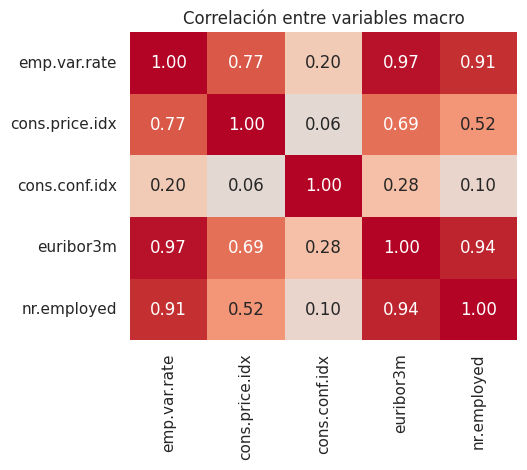

In [127]:
# F1. Escribe el código que muestre un mapa de calor con la matriz de correlación de las variables de la lista macro,
# calculada con ent, con los valores anotados en cada celda.
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(ent[macro].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar=False, ax=ax)
ax.set_title("Correlación entre variables macro")
plt.show()

**Tu observación.** Reporta los pares más correlacionados y la decisión que implican.
\
Podemos observar que la variación del empleo y el euribor3m están intimamente relacionados, incluso más que euribor3m y cons.price.idx (índice de precios al consumidor).
\
Esto puede deberse a que el emp.var.rate (la variación del empleo) causa también cambios en el las tasas de interés.
\
Por el contrario, el par más poco relacionado es el índice de confianza del consumidor y el número de empleados: nr.employed.
\
Esto quizás se deba a la manera de medir el índice de confianza, pues de ser entrevistas, pueden estar sesgadas.

### F2. La variable `duration`

**Por qué.** Una variable puede tener una relación muy fuerte con el objetivo y aun así no ser utilizable. Esto ocurre cuando su valor solo se conoce después del evento que se quiere predecir.

In [128]:
# F2. Escribe el código que muestre el resumen estadístico (describe) de duration por clase de y.
display(ent.groupby("y")["duration"].describe())

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,29238.0,221.148198,208.303557,0.0,95.0,164.0,279.0,4918.0
yes,3712.0,549.398976,397.490060,63.0,252.0,448.0,737.0,4199.0


**Tu respuesta.** ¿Incluirías `duration` como característica de un modelo que se usará para decidir a quién llamar?
\
Lo que pasa es que la duración de la llamada más bien viene después de saber si alguien va a comprar y no al revés.
\
Es más la consecuencia que una causa.
\
Por eso no se puede usar para decidir a quién llamar.
\
Otra cosa que observo es que la duración máxima del "no" es de 4918 segundos y del yes es de 4199, esos valores tan extremos comparados con los mínimos pueden hacer que el modelo predictivo no generalice bien.

**Tu respuesta.** El conjunto está ordenado por fecha y los indicadores económicos varían con el tiempo. ¿Qué implica dividir al azar, como en la parte C, para un modelo que se usará en campañas futuras?
\
Cuando dividimos al azar asumimos que los datos de entrenamiento son representativos de todos los datos y que serán suficientes para que el modelo aprenda qué hacer en cada caso, sin embargo, esto puede no siempre ser cierto, por lo que nos puede llevar a entrenar un modelo sesgado que arroje resultados erróneos.


## Parte G. Hoja de decisiones y justificación del uso de los datos

### G1. Hoja de decisiones

**Por qué.** El producto de un EDA predictivo es una lista de decisiones, cada una con su evidencia. Ninguna decisión se aplica todavía sobre los datos.

Completa la tabla con **al menos siete decisiones**, cada una con un hallazgo de tu análisis (con su cifra), la decisión y el tema del curso donde se aplicaría (preprocesamiento, modelos, evaluación). Debe aparecer al menos una decisión sobre cada uno de estos aspectos: variable no utilizable, valores faltantes o códigos especiales, desbalance de clases, redundancia entre características y asimetría.

Edita esta celda y agrega las filas que necesites.

| Hallazgo (con cifra) | Decisión | Se aplica en |
| --- | --- | --- |
|8597 datos "unknown" |Hay seis columnas con datos "unknown", pero hay una columna: default que tiene 8597, pero se dejan como están para no perder esas filas y tratarlas como categoría adicional |Preprocesamiento |
|Fuerte poder separador, pero solo se conoce post-llamada, 258 seg promedio |La columna "duration" no debe ser usada como característica para hacer predicciones porque solo se conoce hastaque la llamada terminó. |Preprocesamiento|
|12 filas duplicadas |Hay 12 filas duplicadas. Se eliminan las repeticiones pero se dejan las primeras ocurrencias|Preprocesamiento |
|Asimetrías: 3.3 en duration y 4.7 en campaign |Se aplica transformación logarítmica a dos variables pues presentan asimetrías muy marcadas en duration: 3.4 y campaign: 4.7 | Preprocesamiento|
|1 columna con caracteres especiales |Se limpian los datos de la columna "job" pues no hay una consistencia al separar palabras, a veces se usa el punto y a veces guión medio| Preprocesamiento|
|Nombrado de columnas inconsistente |Se cambian los puntos por guiones bajos | Preprocesamiento|
|1 registro sospechoso|Se elimina un registro de un menor de edad, porque teóricamente no puede contratar depósitos a plazos |Preprocesamiento |
|Métricas por desbalance de clases: Un modelo prediciendo solo la clase mayoritaria obtendría 88.7% de exactitud.|Se modifica el método de evaluar al modelo |Evaluación |
|Desbalance de clases: 88.7% de "no" VS 11.3% de "yes".|Podríamos configurar el parámetro class_weight="balanced" en otro modelo para mejorar ese balance |Modelos |
|Redundancia de 3 columnas|Correlación arriba del 90% en las columnas "emp.var.rate", "euribor3m", "nr.employed" |Preprocesamiento |

### G2. Uso de los datos

**Tu respuesta.** En esta actividad, ¿qué partes se hicieron con el conjunto total y cuáles solo con entrenamiento?
\
La parte B: descripción de los datos y detección de problemas de calidad se hizo sobre el conjunto total porque evalúan la calidad e integridad inicial de la base de datos, y así poder hacer un primer filtro.
\
Por el contrario, el cálculo de outliers, comparación entre categorías numéricas y categóricas y correlaciones se ejecutaron únicamente sobre el conjunto de entrenamiento (ent) para evitar la fuga de información hacia los datos con los que se evaluará el modelo final.

**Tu respuesta.** Si hubieras explorado también el conjunto de prueba, ¿qué decisión de tu hoja podría quedar sesgada y cómo se reflejaría en la evaluación final?
\
Si hubiera explorado también el conjunto de prueba ya no tendría sentido pues el modelo conocería aquello que debe de generalizar a partir de los datos de entrenamiento.
\
Es como si le diera las respuestas de lo que le voy a preguntar para ver si entendió.